In [75]:
import pandas as pd
import glob
import json
import os

sample_path = f'{os.getcwd()}/../workspace/samples/'

x86_samples = 'x86-gemini-pro'
arm_samples = 'arm-gemini-pro'

def get_rows(path):

    summaries = sorted(glob.glob(f'{path}/*/agent_repair/summary.json'))

    rows = []
    for sample, path in enumerate(summaries):

        with open(path, 'r') as f:
            data = json.load(f)
        
        arch = data['summary']['arch']
        model = data['models']['llm']

        for attempt in data['attempts']:
            rows.append({
            'sample': sample,
            'arch': arch,
            'model': model,
            'attempt': attempt['attempt'],
            'boot_succeeded': attempt['summary']['boot_succeeded'],
            'define': attempt['changes']['define'],
            'undefine': attempt['changes']['undefine'],
            'original_config': f'{os.path.dirname(path)}/../.config',
            'modified_config': f'{os.path.dirname(path)}/attempt_{attempt["attempt"]}/modified.config',
            'edit_distance': data['summary']['edit_distance'],
            'total_constraints': data['summary']['total_constraints'],
            'define': attempt['changes']['define'],
            'undefine': attempt['changes']['undefine'],
        })

    return rows

rows = get_rows(f'{sample_path}/{x86_samples}') + get_rows(f'{sample_path}/{arm_samples}')
df = pd.DataFrame(rows)

print(df.groupby('model')['sample'].nunique())

df.head()

model
gemini-3.1-pro-preview    50
Name: sample, dtype: int64


,sample,arch,model,attempt,boot_succeeded,define,undefine,original_config,modified_config,edit_distance,total_constraints
0,0,x86_64,gemini-3.1-pro-preview,0,no,None,None,/Users/user/Documents/UCF/Thesis/KBoo...,/Users/user/Documents/UCF/Thesis/KBoo...,2629,79
1,0,x86_64,gemini-3.1-pro-preview,1,timeout,[],[CONFIG_KASAN],/Users/user/Documents/UCF/Thesis/KBoo...,/Users/user/Documents/UCF/Thesis/KBoo...,2629,79
2,0,x86_64,gemini-3.1-pro-preview,2,panic,"[CONFIG_TTY, CONFIG_SERIAL_8250, CONFIG_SERIAL...",[CONFIG_KASAN],/Users/user/Documents/UCF/Thesis/KBoo...,/Users/user/Documents/UCF/Thesis/KBoo...,2629,79
3,0,x86_64,gemini-3.1-pro-preview,3,timeout,[],"[CONFIG_KASAN, CONFIG_KCSAN]",/Users/user/Documents/UCF/Thesis/KBoo...,/Users/user/Documents/UCF/Thesis/KBoo...,2629,79
4,0,x86_64,gemini-3.1-pro-preview,4,panic,"[CONFIG_TTY, CONFIG_SERIAL_8250, CONFIG_SERIAL...","[CONFIG_KASAN, CONFIG_KCSAN]",/Users/user/Documents/UCF/Thesis/KBoo...,/Users/user/Documents/UCF/Thesis/KBoo...,2629,79


In [76]:
def parse_config(path):
    with open(path, 'r') as f:
        lines = f.readlines()

    options = set()

    for line in lines:
        if '=' in line:
            options.add(line.strip().split('=')[0])
            
    return options

def jaccard_similarity(a, b):
    return len(a & b) / len(a | b) if a | b else 1.0

# Between Samples

In [77]:
import numpy as np

repaired_samples = df[df['boot_succeeded'] == 'yes']

def get_before_after_scores(samples):

    num_samples = samples['sample'].nunique()

    before = np.zeros((num_samples, num_samples))
    after = np.zeros((num_samples, num_samples))

    for i, a in enumerate(samples['sample'].unique()):
        for j, b in enumerate(samples['sample'].unique()):

            if i > j:
                continue

            config_a_before = parse_config(samples[samples['sample'] == a]['original_config'].iloc[0])
            config_b_before = parse_config(samples[samples['sample'] == b]['original_config'].iloc[0])
            score = jaccard_similarity(config_a_before, config_b_before)
            
            before[i, j] = score
            before[j, i] = score

            config_a_after = parse_config(samples[samples['sample'] == a]['modified_config'].iloc[0])
            config_b_after = parse_config(samples[samples['sample'] == b]['modified_config'].iloc[0])
            score = jaccard_similarity(config_a_after, config_b_after)
            
            after[i, j] = score
            after[j, i] = score

    return before, after

In [78]:
x86_before, x86_after = get_before_after_scores(repaired_samples[repaired_samples['arch'] == 'x86_64'])
arm_before, arm_after = get_before_after_scores(repaired_samples[repaired_samples['arch'] == 'arm64'])

x86_sample_similarity = pd.DataFrame({
    'before': x86_before[np.triu_indices_from(x86_before, k=1)],
    'after': x86_after[np.triu_indices_from(x86_after, k=1)]
})

print('x86 Sample Similarity:')
print(x86_sample_similarity.describe())

arm_sample_similarity = pd.DataFrame({
    'before': arm_before[np.triu_indices_from(arm_before, k=1)],
    'after': arm_after[np.triu_indices_from(arm_after, k=1)]
})

print('\n\nARM Sample Similarity:')
print(arm_sample_similarity.describe())

x86 Sample Similarity:
           before       after
count  990.000000  990.000000
mean     0.306674    0.325459
std      0.040249    0.039233
min      0.218123    0.233551
25%      0.277032    0.296018
50%      0.303255    0.323432
75%      0.332277    0.353091
max      0.438393    0.446556


ARM Sample Similarity:
            before        after
count  1081.000000  1081.000000
mean      0.306533     0.318755
std       0.032191     0.031284
min       0.213282     0.235179
25%       0.282903     0.295899
50%       0.304710     0.319155
75%       0.328842     0.341515
max       0.416084     0.415750


Text(0.5, 1.0, 'ARM After Repair')

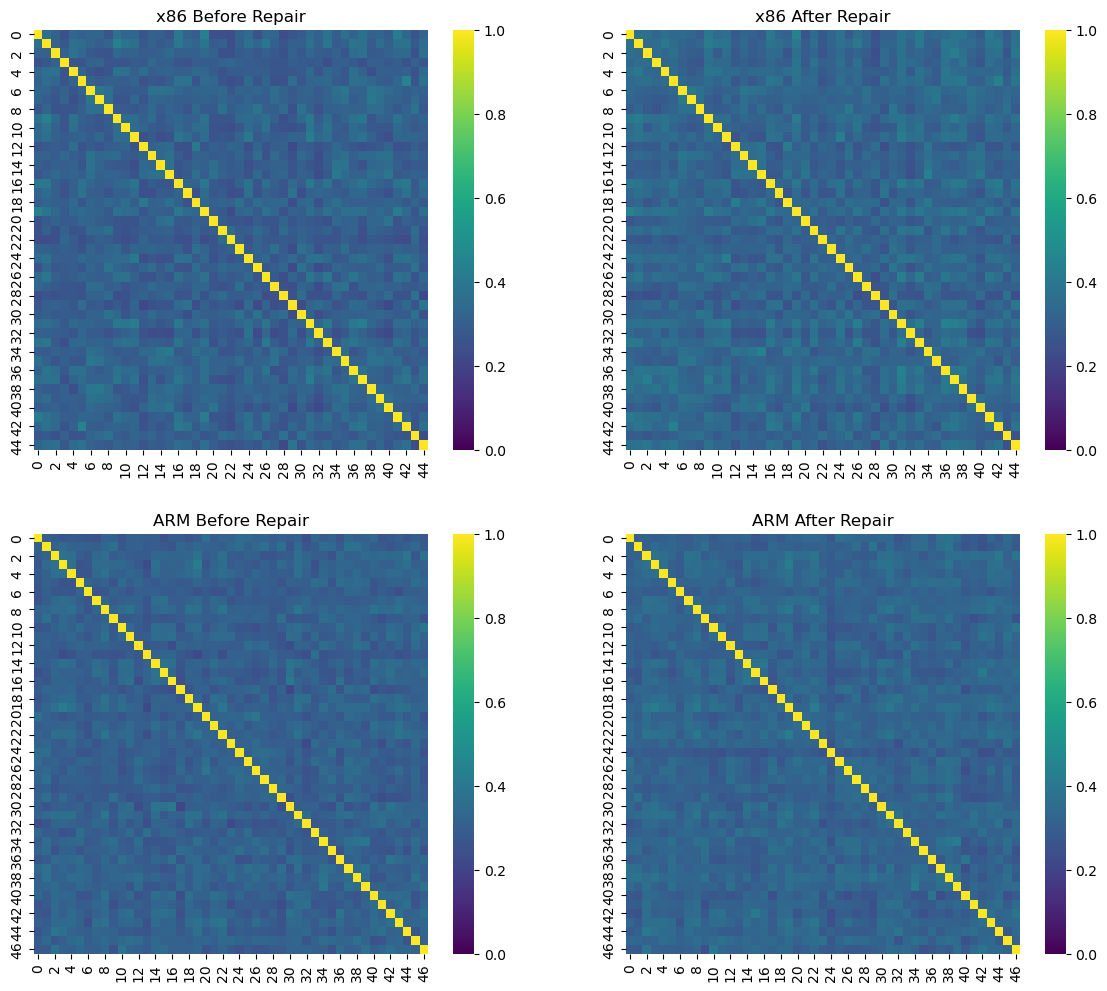

In [79]:
from matplotlib import pyplot as plt
import seaborn as sns

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 12))

sns.heatmap(x86_before, vmin=0, vmax=1, fmt='.2f', cmap='viridis', ax=ax1)
ax1.set_title('x86 Before Repair')

sns.heatmap(x86_after, vmin=0, vmax=1, fmt='.2f', cmap='viridis', ax=ax2)
ax2.set_title('x86 After Repair')

sns.heatmap(arm_before, vmin=0, vmax=1, fmt='.2f', cmap='viridis', ax=ax3)
ax3.set_title('ARM Before Repair')

sns.heatmap(arm_after, vmin=0, vmax=1, fmt='.2f', cmap='viridis', ax=ax4)
ax4.set_title('ARM After Repair')

In [87]:
from scipy.stats import ttest_rel

x86_before_vals = x86_before[np.triu_indices_from(x86_before, k=1)]
x86_after_vals = x86_after[np.triu_indices_from(x86_after, k=1)]

arm_before_vals = arm_before[np.triu_indices_from(arm_before, k=1)]
arm_after_vals = arm_after[np.triu_indices_from(arm_after, k=1)]

x86_before_after_sample_similarity = pd.DataFrame({
    'x86_before': x86_before_vals,
    'x86_after': x86_after_vals,
})

arm_before_after_sample_similarity = pd.DataFrame({
    'arm_before': arm_before_vals,
    'arm_after': arm_after_vals,
})

print(x86_before_after_sample_similarity.describe().to_string())
print(arm_before_after_sample_similarity.describe().to_string())

x86_t_stat, x86_p_value = ttest_rel(x86_before_vals, x86_after_vals)
arm_t_stat, arm_p_value = ttest_rel(arm_before_vals, arm_after_vals)

print(f'x86 t-statistic: {x86_t_stat}, p-value: {x86_p_value}')
print(f'ARM t-statistic: {arm_t_stat}, p-value: {arm_p_value}')

       x86_before   x86_after
count  990.000000  990.000000
mean     0.306674    0.325459
std      0.040249    0.039233
min      0.218123    0.233551
25%      0.277032    0.296018
50%      0.303255    0.323432
75%      0.332277    0.353091
max      0.438393    0.446556
        arm_before    arm_after
count  1081.000000  1081.000000
mean      0.306533     0.318755
std       0.032191     0.031284
min       0.213282     0.235179
25%       0.282903     0.295899
50%       0.304710     0.319155
75%       0.328842     0.341515
max       0.416084     0.415750
x86 t-statistic: -25.816594859469586, p-value: 9.240139785228254e-113
ARM t-statistic: -17.77939514773895, p-value: 3.1554037360531e-62


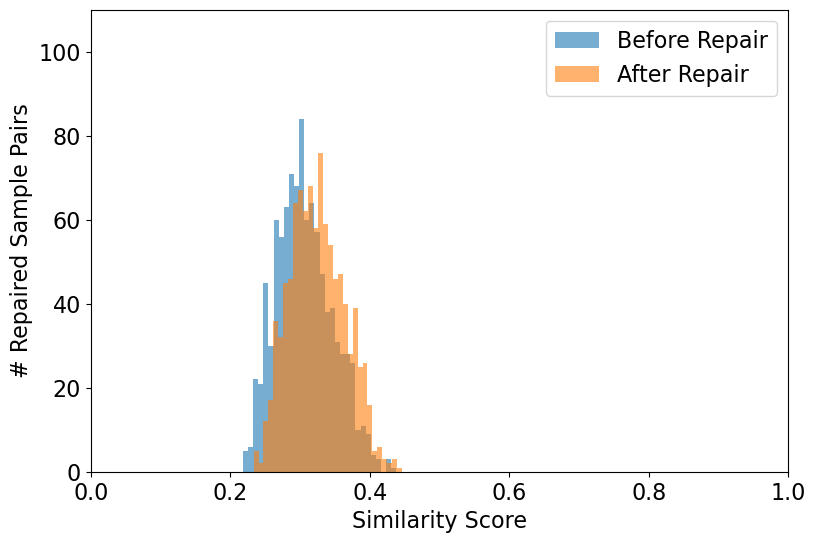

In [81]:
fig, ax = plt.subplots(figsize=(9, 6))

x86_before_vals = x86_before[np.triu_indices_from(x86_before, k=1)]
x86_after_vals = x86_after[np.triu_indices_from(x86_after, k=1)]

ax.hist(x86_before_vals, bins=30, alpha=0.6, label='Before Repair')
ax.hist(x86_after_vals, bins=30, alpha=0.6, label='After Repair')

ax.set_xlabel('Similarity Score', fontsize=16)
ax.set_xlim(0, 1)

ax.set_ylabel('# Repaired Sample Pairs', fontsize=16)
ax.set_ylim(0, 110)

ax.legend(fontsize=16)
ax.tick_params(axis='both', labelsize=16)

plt.savefig('x86-paired-similarity.pdf', format='pdf', bbox_inches='tight')
plt.show()

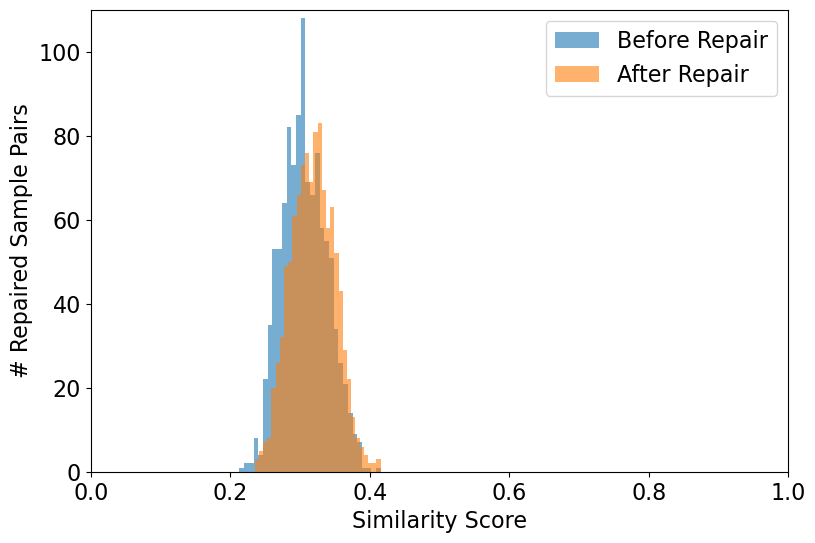

In [82]:
fig, ax = plt.subplots(figsize=(9, 6))

arm_before_vals = arm_before[np.triu_indices_from(arm_before, k=1)]
arm_after_vals = arm_after[np.triu_indices_from(arm_after, k=1)]

ax.hist(arm_before_vals, bins=30, alpha=0.6, label='Before Repair')
ax.hist(arm_after_vals, bins=30, alpha=0.6, label='After Repair')

ax.set_xlabel('Similarity Score', fontsize=16)
ax.set_xlim(0, 1)

ax.set_ylabel('# Repaired Sample Pairs', fontsize=16)
ax.set_ylim(0, 110)

ax.legend(fontsize=16)
ax.tick_params(axis='both', labelsize=16)

plt.savefig('arm-paired-similarity.pdf', format='pdf', bbox_inches='tight')
plt.show()

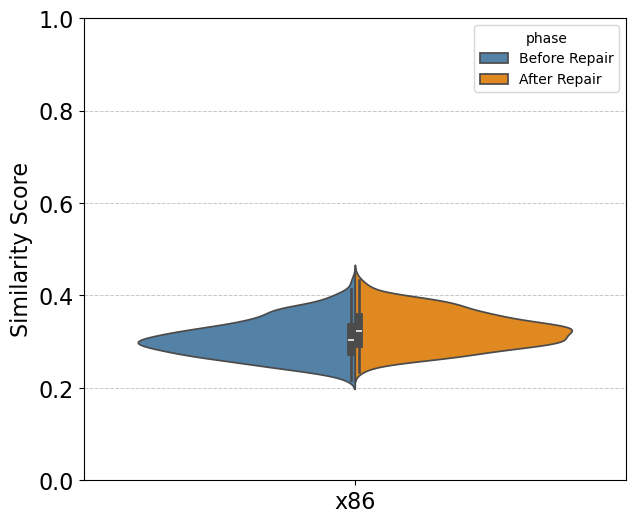

In [84]:
import seaborn as sns
import pandas as pd

df_plot = pd.DataFrame({
    'score': np.concatenate([x86_before_vals, x86_after_vals]),
    'phase': ['Before Repair'] * len(x86_before_vals) + ['After Repair'] * len(x86_after_vals),
    'group': ['x86'] * (len(x86_before_vals) + len(x86_after_vals))
})

fig, ax = plt.subplots(figsize=(7, 6))
sns.violinplot(
    data=df_plot, x='group', y='score', hue='phase', split=True,
    palette={'Before Repair': 'steelblue', 'After Repair': 'darkorange'},
    ax=ax
)
ax.set_xlabel('')
ax.set_ylabel('Similarity Score', fontsize=16)
ax.set_ylim(0, 1)
ax.tick_params(axis='both', labelsize=16)
ax.grid(axis='y', linestyle='--', linewidth=0.7, alpha=0.7)
ax.set_axisbelow(True)
plt.show()

In [ ]:
from itertools import combinations

last_attempts = df[df['boot_succeeded'] == 'yes']
last_x86_attempts = last_attempts[last_attempts['arch'] == 'x86_64']
last_arm_attempts = last_attempts[last_attempts['arch'] == 'arm64']

def get_change_similarities(samples):

    rows = list(samples.itertuples())
    data = []

    for a, b in combinations(rows, 2):

        a_defines, b_defines = set(a.define), set(b.define)
        a_undefines, b_undefines = set(a.undefine), set(b.undefine)

        a_suggestions = set(a_defines) | set([f'!{opt}' for opt in a_undefines])
        b_suggestions = set(b_defines) | set([f'!{opt}' for opt in b_undefines])

        data.append({
            'define': jaccard_similarity(a_defines, b_defines),
            'undefine': jaccard_similarity(a_undefines, b_undefines),
            'suggestions': jaccard_similarity(a_suggestions, b_suggestions),
        })

    return pd.DataFrame(data)

x86_change_similarity = get_change_similarities(last_x86_attempts)
arm_change_similarity = get_change_similarities(last_arm_attempts)

print('x86 Change Similarity:')
print(x86_change_similarity.describe())

print('\n\nARM Change Similarity:')
print(arm_change_similarity.describe())

x86 Change Similarity:
           define    undefine  suggestions
count  990.000000  990.000000   990.000000
mean     0.225839    0.111470     0.175085
std      0.095881    0.078719     0.069336
min      0.000000    0.000000     0.000000
25%      0.153846    0.050956     0.123004
50%      0.219756    0.103448     0.174112
75%      0.292998    0.161146     0.224784
max      0.566038    0.440000     0.396040


ARM Change Similarity:
            define     undefine  suggestions
count  1081.000000  1081.000000  1081.000000
mean      0.247586     0.123589     0.182318
std       0.091450     0.083960     0.067549
min       0.027778     0.000000     0.027027
25%       0.182692     0.055556     0.132353
50%       0.250000     0.116279     0.182796
75%       0.304348     0.187500     0.229008
max       0.580645     0.406250     0.417722


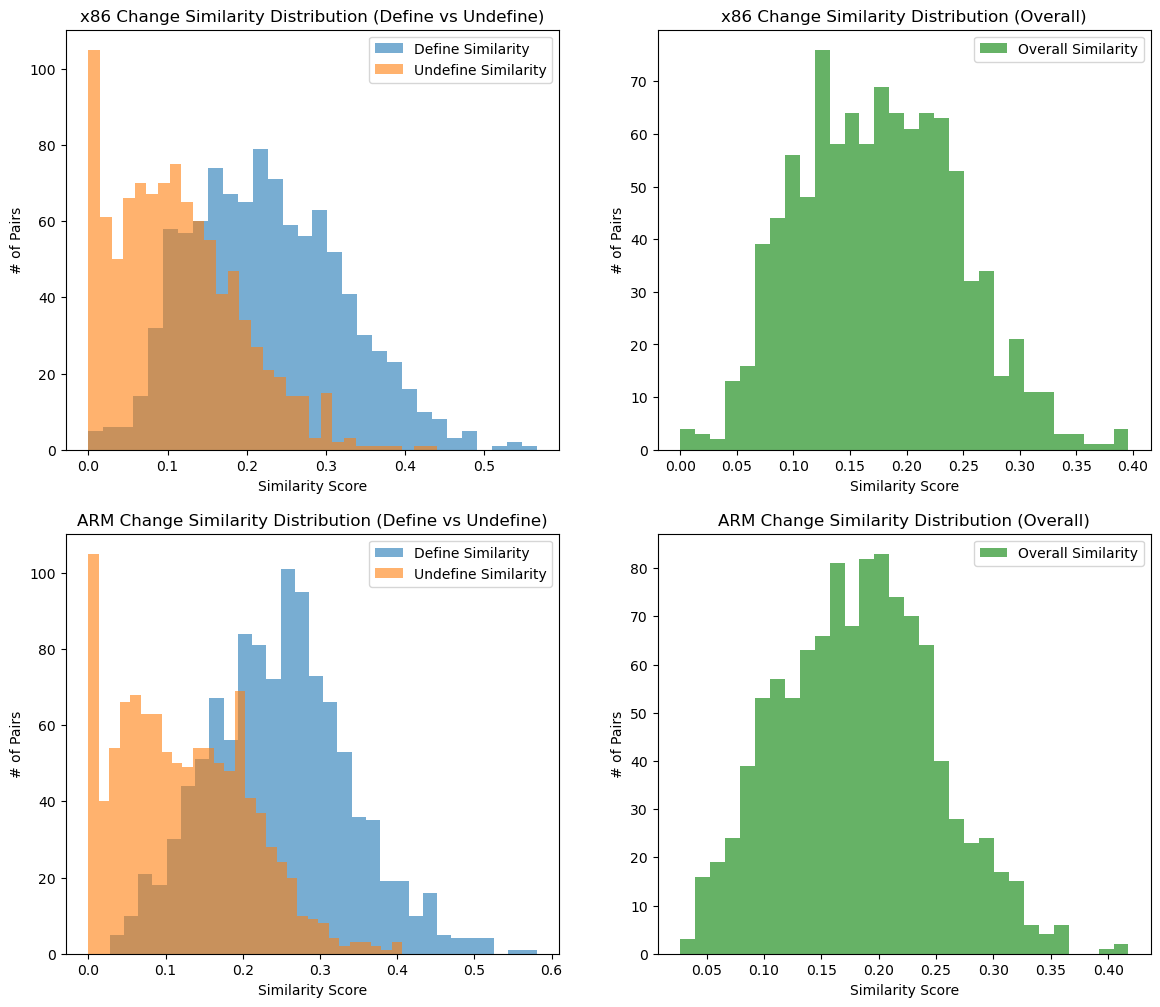

In [ ]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 12))

ax1.hist(x86_change_similarity['define'], bins=30, alpha=0.6, label='Define Similarity')
ax1.hist(x86_change_similarity['undefine'], bins=30, alpha=0.6, label='Undefine Similarity')
ax1.set_xlabel('Similarity Score')
ax1.set_ylabel('# of Pairs')
ax1.set_title('x86 Change Similarity Distribution (Define vs Undefine)')
ax1.legend()

ax2.hist(x86_change_similarity['suggestions'], bins=30, alpha=0.6, label='Overall Similarity', color='green')
ax2.set_xlabel('Similarity Score')
ax2.set_ylabel('# of Pairs')
ax2.set_title('x86 Change Similarity Distribution (Overall)')
ax2.legend()

ax3.hist(arm_change_similarity['define'], bins=30, alpha=0.6, label='Define Similarity')
ax3.hist(arm_change_similarity['undefine'], bins=30, alpha=0.6, label='Undefine Similarity')
ax3.set_xlabel('Similarity Score')
ax3.set_ylabel('# of Pairs')
ax3.set_title('ARM Change Similarity Distribution (Define vs Undefine)')
ax3.legend()

ax4.hist(arm_change_similarity['suggestions'], bins=30, alpha=0.6, label='Overall Similarity', color='green')
ax4.set_xlabel('Similarity Score')
ax4.set_ylabel('# of Pairs')
ax4.set_title('ARM Change Similarity Distribution (Overall)')
ax4.legend()

plt.savefig('change-similarity-distribution.pdf', format='pdf', bbox_inches='tight')
plt.show()

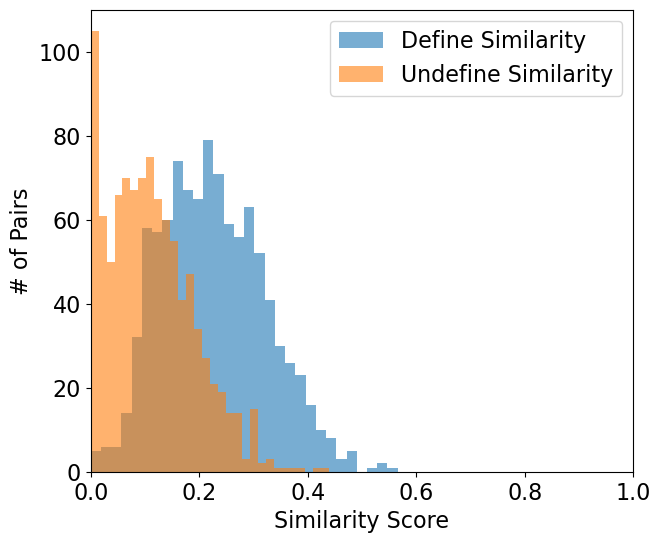

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.hist(x86_change_similarity['define'], bins=30, alpha=0.6, label='Define Similarity')
ax.hist(x86_change_similarity['undefine'], bins=30, alpha=0.6, label='Undefine Similarity')

ax.set_xlabel('Similarity Score', fontsize=16)
ax.set_xlim(0, 1)

ax.set_ylabel('# of Pairs', fontsize=16)
ax.set_ylim(0, 110)

ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=16)

plt.savefig('x86-suggestion-similarity.pdf', format='pdf', bbox_inches='tight')
plt.show()

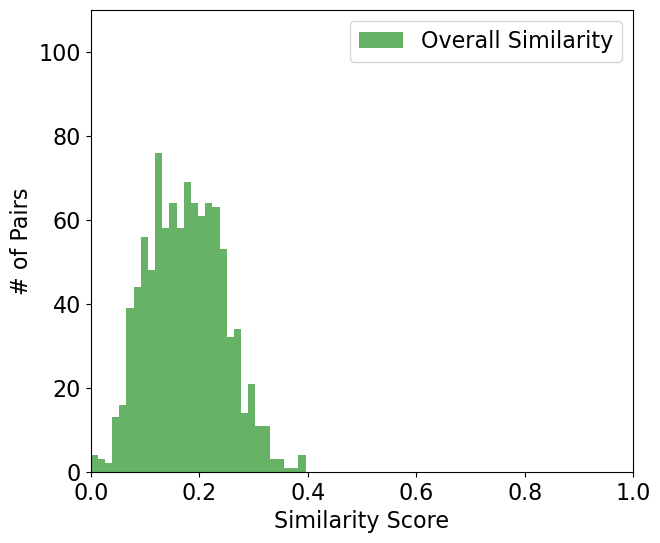

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.hist(x86_change_similarity['suggestions'], bins=30, alpha=0.6, label='Overall Similarity', color='green')

ax.set_xlabel('Similarity Score', fontsize=16)
ax.set_xlim(0, 1)

ax.set_ylabel('# of Pairs', fontsize=16)
ax.set_ylim(0, 110)

ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=16)

plt.savefig('x86-suggestion-list-similarity.pdf', format='pdf', bbox_inches='tight')
plt.show()

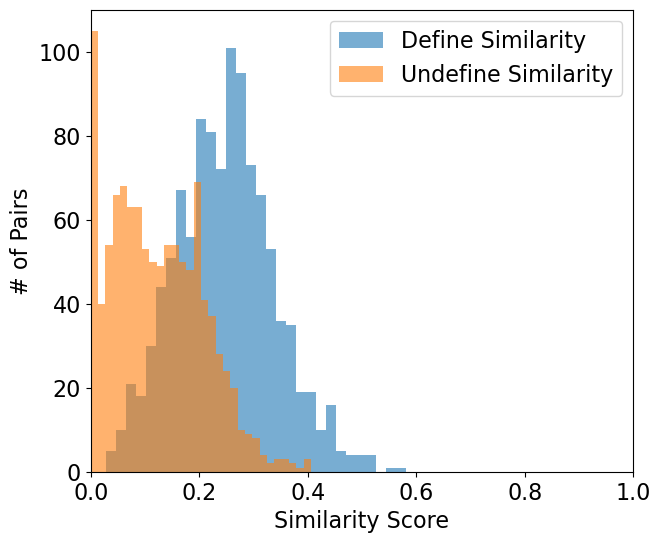

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.hist(arm_change_similarity['define'], bins=30, alpha=0.6, label='Define Similarity')
ax.hist(arm_change_similarity['undefine'], bins=30, alpha=0.6, label='Undefine Similarity')

ax.set_xlabel('Similarity Score', fontsize=16)
ax.set_xlim(0, 1)

ax.set_ylabel('# of Pairs', fontsize=16)
ax.set_ylim(0, 110)

ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=16)

plt.savefig('arm-suggestion-similarity.pdf', format='pdf', bbox_inches='tight')
plt.show()

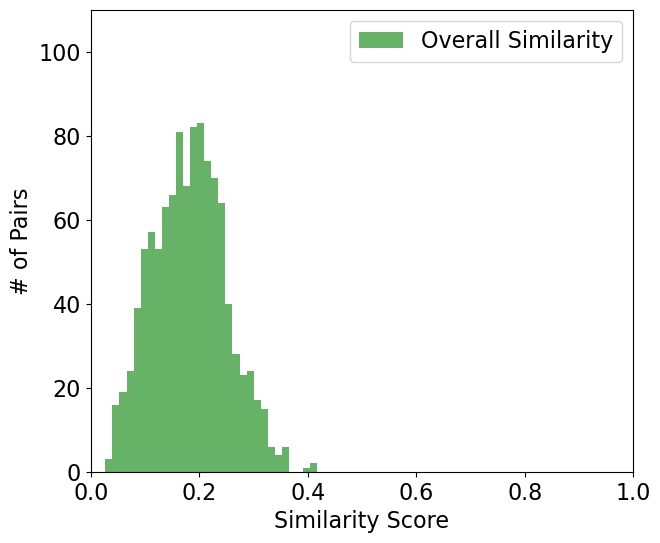

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.hist(arm_change_similarity['suggestions'], bins=30, alpha=0.6, label='Overall Similarity', color='green')

ax.set_xlabel('Similarity Score', fontsize=16)
ax.set_xlim(0, 1)

ax.set_ylabel('# of Pairs', fontsize=16)
ax.set_ylim(0, 110)

ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=16)

plt.savefig('arm-suggestion-list-similarity.pdf', format='pdf', bbox_inches='tight')
plt.show()

count    990.000000
mean       0.175085
std        0.069336
min        0.000000
25%        0.123004
50%        0.174112
75%        0.224784
max        0.396040
Name: suggestions, dtype: float64


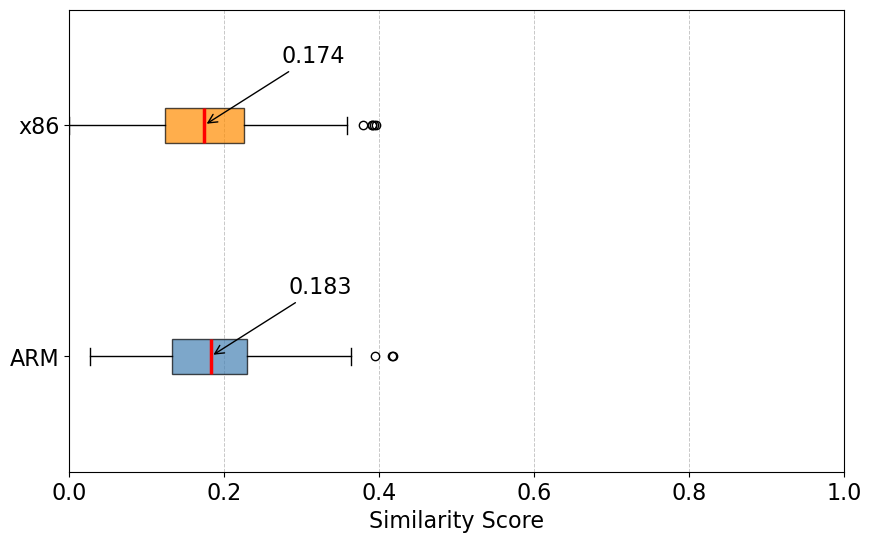

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['steelblue', 'darkorange']

change_similarity = [arm_change_similarity['suggestions'], x86_change_similarity['suggestions']]
bp = ax.boxplot(change_similarity, labels=['ARM', 'x86'], patch_artist=True, vert=False)

print(change_similarity[1].describe())
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

for i, median in enumerate(bp['medians']):
    median.set_color('red')
    median.set_linewidth(2.5)
    x = median.get_xdata()[1]
    y = i + 1
    ax.annotate(f'{x:.3f}', xy=(x, y), xytext=(x + 0.1, y + 0.3), fontsize=16, color='black', va='center', arrowprops=dict(arrowstyle='->', color='black'))

ax.set_xlabel('Similarity Score', fontsize=16)
ax.grid(axis='x', linestyle='--', linewidth=0.7, alpha=0.7)
ax.tick_params(axis='both', labelsize=16)
ax.set_xlim(0, 1)

plt.savefig('change-similarity-boxplot.pdf', format='pdf', bbox_inches='tight')
plt.show()

# Between Attempts

In [ ]:
last_attempts = df[df['boot_succeeded'] == 'yes'].copy()

last_attempts['before_after_similarity'] = last_attempts.apply(lambda row: jaccard_similarity(
    parse_config(row['original_config']),
    parse_config(row['modified_config'])
), axis=1)

last_attempts['num_defines'] = last_attempts['define'].apply(len)
last_attempts['num_undefines'] = last_attempts['undefine'].apply(len)
last_attempts['total_changes'] = last_attempts['num_defines'] + last_attempts['num_undefines']

print('x86 Before-After Similarity:')
print(last_attempts[last_attempts['arch'] == 'x86_64'][['before_after_similarity', 'edit_distance', 'num_defines', 'num_undefines', 'total_changes']].describe().to_string())

print('\n\nARM Before-After Similarity:')
print(last_attempts[last_attempts['arch'] == 'arm64'][['before_after_similarity', 'edit_distance', 'num_defines', 'num_undefines', 'total_changes']].describe().to_string())

print('\n\nOverall Before-After Similarity:')
print(last_attempts[['before_after_similarity', 'edit_distance', 'num_defines', 'num_undefines', 'total_changes']].describe().to_string())

x86 Before-After Similarity:
       before_after_similarity  edit_distance  num_defines  num_undefines  total_changes
count                45.000000      45.000000    45.000000      45.000000      45.000000
mean                  0.851343    2495.955556    32.622222      24.933333      57.555556
std                   0.088025    1261.352520    18.113642      17.000535      28.936887
min                   0.613361     257.000000     5.000000       1.000000      12.000000
25%                   0.826946    1663.000000    19.000000      11.000000      33.000000
50%                   0.852813    2253.000000    29.000000      21.000000      53.000000
75%                   0.913010    3568.000000    39.000000      37.000000      76.000000
max                   0.986170    5671.000000    97.000000      69.000000     140.000000


ARM Before-After Similarity:
       before_after_similarity  edit_distance  num_defines  num_undefines  total_changes
count                47.000000      47.000000    4

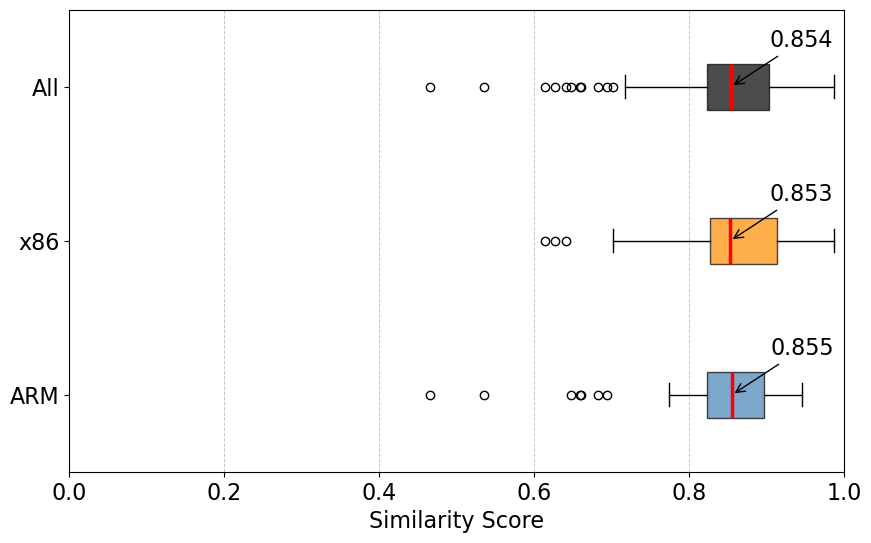

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))                                   

before_after_similarity_data = [
    last_attempts[last_attempts['arch'] == 'arm64']['before_after_similarity'],
    last_attempts[last_attempts['arch'] == 'x86_64']['before_after_similarity'],
    last_attempts['before_after_similarity'],
]

bp = ax.boxplot(before_after_similarity_data, labels=['ARM', 'x86', 'All'], patch_artist=True, vert=False)

for patch, color in zip(bp['boxes'], ['steelblue', 'darkorange', 'black']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

for i, median in enumerate(bp['medians']):
    median.set_color('red')
    median.set_linewidth(2.5)
    x = median.get_xdata()[1]
    y = i + 1
    ax.annotate(f'{x:.3f}', xy=(x, y), xytext=(x + 0.05, y + 0.3), fontsize=16, color='black', va='center', arrowprops=dict(arrowstyle='->', color='black'))

ax.set_xlabel('Similarity Score', fontsize=16)
ax.grid(axis='x', linestyle='--', linewidth=0.7, alpha=0.7)
ax.tick_params(axis='both', labelsize=16)
ax.set_xlim(0, 1)

plt.savefig('preservation.pdf', format='pdf', bbox_inches='tight')
plt.show()